<a href="https://colab.research.google.com/github/miriamamin1213-ux/Ablation_studies/blob/main/HancockDT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Rows: 332 | 3-fold cross-validation across the entire eligible dataset
Class counts: {0: 191, 1: 141}
Fold 1/3 | best parameters: {'ccp_alpha': 0.0, 'class_weight': {0: np.float64(0.8700787401574803), 1: np.float64(1.175531914893617)}, 'criterion': 'gini', 'max_depth': 7, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 2, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'} | threshold: 0.850
Fold 2/3 | best parameters: {'ccp_alpha': 0.0, 'class_weight': {0: np.float64(0.8700787401574803), 1: np.float64(1.175531914893617)}, 'criterion': 'gini', 'max_depth': 4, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 10, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_s

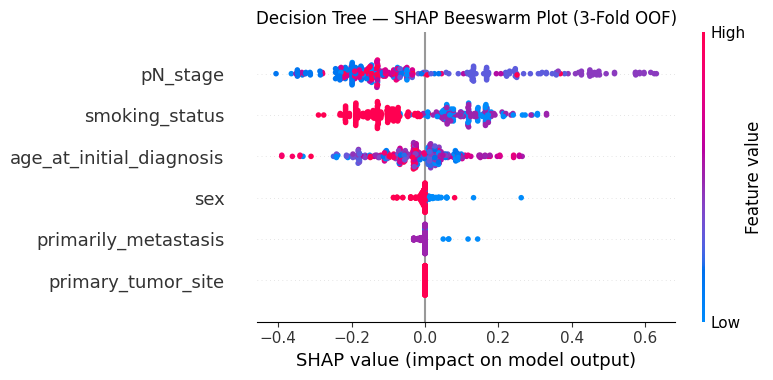

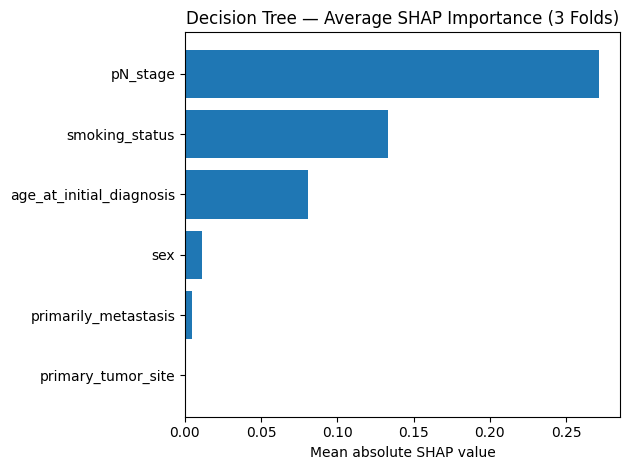

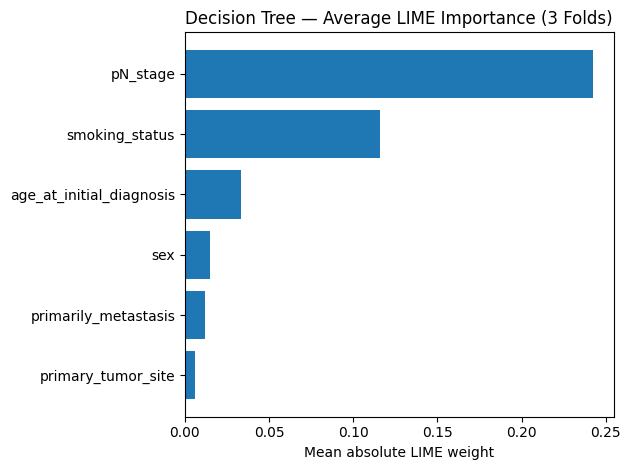

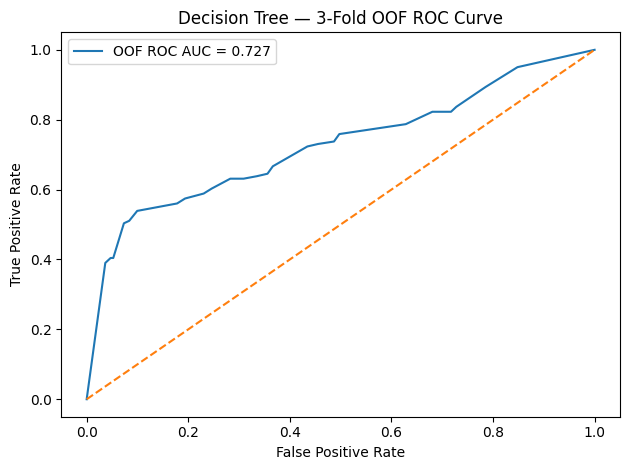

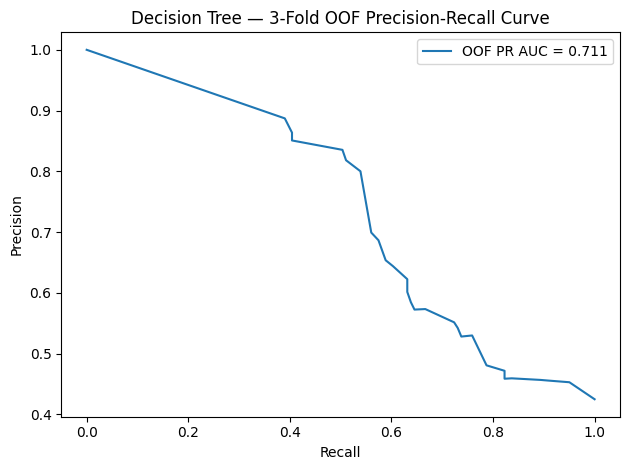

Saved results to: /content/drive/MyDrive/DT_results


In [4]:
# ============================================================
# DECISION TREE — HANCOCK HPV CLASSIFIER
# Shared data preparation | Seed 42 | No SMOTE
# ============================================================
import os, json, random, warnings, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
from sklearn.model_selection import StratifiedKFold, ParameterGrid
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix, classification_report, roc_curve, precision_recall_curve)
warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
drive.mount("/content/drive")
# ------------------------------------------------------------
# 1. LOAD AND PREPARE DATA
# ------------------------------------------------------------
BASE = "/content/drive/MyDrive"
OUT_DIR = os.path.join(BASE, "DT_results")
os.makedirs(OUT_DIR, exist_ok=True)
def load_json_table(path):
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)
    if isinstance(obj, list):
        return pd.DataFrame(obj)
    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if key in obj and isinstance(obj[key], list):
                return pd.DataFrame(obj[key])
        return pd.DataFrame(obj)
    raise ValueError(f"Cannot read table from {path}")
clinical = load_json_table(os.path.join(BASE, "clinical_data.json"))
pathology = load_json_table(os.path.join(BASE, "pathological_data.json"))
if "patient_id" not in clinical or "patient_id" not in pathology:
    raise KeyError("Both files must contain patient_id.")
df = clinical.merge(pathology, on="patient_id", how="left", suffixes=("", "_path"))
target_candidates = ["hpv_association_p16", "hpv_association_p16_path"]
target_col = next((c for c in target_candidates if c in df.columns), None)
if target_col is None:
    raise KeyError("HPV target column was not found.")
feature_candidates = {
    "age_at_initial_diagnosis": ["age_at_initial_diagnosis"],
    "sex": ["sex"],
    "smoking_status": ["smoking_status"],
    "primary_tumor_site": ["primary_tumor_site"],
    "primarily_metastasis": ["primarily_metastasis"],
    "pN_stage": ["pN_stage", "pN_stage_path", "pathological_N_stage", "pathologic_N_stage", "pathological_n_stage"]
}
rename_map = {}
for name, candidates in feature_candidates.items():
    match = next((c for c in candidates if c in df.columns), None)
    if match is None:
        raise KeyError(f"Missing predictor {name}; checked {candidates}")
    if match != name:
        rename_map[match] = name
df = df.rename(columns=rename_map)
features = list(feature_candidates.keys())
def normalize_label(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip().lower()
    if value in {"negative", "neg", "0", "false", "no"}:
        return 0
    if value in {"positive", "pos", "1", "true", "yes"}:
        return 1
    try:
        number = float(value)
        if number in (0.0, 1.0):
            return int(number)
    except (ValueError, TypeError):
        pass
    return np.nan
df["HPV_Label"] = df[target_col].map(normalize_label)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)
df = df[["patient_id"] + features + ["HPV_Label"]].copy()
print("Rows:", len(df), "| 3-fold cross-validation across the entire eligible dataset")
print("Class counts:", df["HPV_Label"].value_counts().sort_index().to_dict())
numeric_features = ["age_at_initial_diagnosis"]
categorical_features = [c for c in features if c not in numeric_features]
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)
# ------------------------------------------------------------
# 2. SELECT TREE SETTINGS USING EACH VALIDATION FOLD ONLY
# ------------------------------------------------------------
grid = {
    "max_depth": [2, 3, 4, 5, 7, None],
    "min_samples_split": [2, 5, 10, 15],
    "min_samples_leaf": [2, 5, 10],
    "criterion": ["gini", "entropy"]
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
fold_metrics = []
tuning_rows = []
fold_importances = []
oof_prob = np.zeros(len(df))
oof_pred = np.zeros(len(df), dtype=int)
oof_fold = np.zeros(len(df), dtype=int)
shap_fold_importance = []
shap_plot_values = []
shap_plot_features = []
lime_fold_importance = []
feature_groups = None
for fold, (train_idx, val_idx) in enumerate(cv.split(df[features], df["HPV_Label"]), 1):
    train = df.iloc[train_idx].copy()
    val = df.iloc[val_idx].copy()
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)
    preprocessor = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", encoder)]), categorical_features)
    ])
    X_train = preprocessor.fit_transform(train[features])
    X_val = preprocessor.transform(val[features])
    y_train = train["HPV_Label"].to_numpy()
    y_val = val["HPV_Label"].to_numpy()
    counts = np.bincount(y_train, minlength=2)
    class_weights = {i: len(y_train) / (2 * counts[i]) for i in range(2)}
    best_model = None
    best_threshold = 0.5
    best_key = None
    for params in ParameterGrid(grid):
        candidate = DecisionTreeClassifier(**params, class_weight=class_weights, random_state=SEED)
        candidate.fit(X_train, y_train)
        val_prob = candidate.predict_proba(X_val)[:, 1]
        thresholds = np.linspace(0.10, 0.90, 81)
        scores = [balanced_accuracy_score(y_val, (val_prob >= t).astype(int)) for t in thresholds]
        max_score = max(scores)
        threshold = min((t for t, score in zip(thresholds, scores) if score == max_score), key=lambda t: abs(t - 0.5))
        val_pred = (val_prob >= threshold).astype(int)
        auc = roc_auc_score(y_val, val_prob) if len(np.unique(y_val)) == 2 else 0.5
        pr_auc = average_precision_score(y_val, val_prob)
        key = (max_score, auc, pr_auc)
        tuning_rows.append({"fold": fold, **params, "validation_balanced_accuracy": max_score, "validation_roc_auc": auc, "validation_pr_auc": pr_auc, "threshold": float(threshold)})
        if best_key is None or key > best_key:
            best_key, best_model, best_threshold = key, candidate, float(threshold)
    val_prob = best_model.predict_proba(X_val)[:, 1]
    val_pred = (val_prob >= best_threshold).astype(int)
    oof_prob[val_idx] = val_prob
    oof_pred[val_idx] = val_pred
    oof_fold[val_idx] = fold
    fold_metrics.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y_val, val_pred),
        "Balanced_Accuracy": balanced_accuracy_score(y_val, val_pred),
        "Precision": precision_score(y_val, val_pred, zero_division=0),
        "Recall": recall_score(y_val, val_pred, zero_division=0),
        "F1": f1_score(y_val, val_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_val, val_prob) if len(np.unique(y_val)) == 2 else np.nan,
        "PR_AUC": average_precision_score(y_val, val_prob),
        "Threshold": best_threshold
    })
    names = list(preprocessor.get_feature_names_out())
    groups = {}
    for i, name in enumerate(names):
        clean = name.split("__", 1)[-1]
        original = next((f for f in sorted(features, key=len, reverse=True) if clean == f or clean.startswith(f + "_")), clean)
        groups.setdefault(original, []).append(i)
    feature_groups = groups
    importance = np.zeros(len(features))
    for j, feature in enumerate(features):
        importance[j] = best_model.feature_importances_[groups.get(feature, [])].sum()
    fold_importances.append(importance)
    try:
        import shap
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
        import shap
    explainer = shap.TreeExplainer(best_model)
    shap_values = explainer.shap_values(X_val)
    if isinstance(shap_values, list):
        shap_values = shap_values[1] if len(shap_values) > 1 else shap_values[0]
    elif hasattr(shap_values, "values"):
        shap_values = shap_values.values
    shap_values = np.asarray(shap_values)
    if shap_values.ndim == 3:
        shap_values = shap_values[:, :, 1] if shap_values.shape[-1] == 2 else shap_values[1]
    # Sum encoded-column SHAP contributions back to the six original features.
    grouped_shap = np.column_stack([
        shap_values[:, groups.get(feature, [])].sum(axis=1)
        if groups.get(feature) else np.zeros(len(val))
        for feature in features
    ])
    shap_plot_values.append(pd.DataFrame(grouped_shap, columns=features))
    # Numeric display values are used for beeswarm colouring; category codes
    # identify categories and are not intended as an ordinal clinical scale.
    display_values = pd.DataFrame(index=val.index)
    for feature in features:
        if feature in numeric_features:
            display_values[feature] = pd.to_numeric(val[feature], errors="coerce")
        else:
            categories = sorted(df[feature].dropna().astype(str).unique())
            display_values[feature] = pd.Categorical(
                val[feature].astype(str), categories=categories
            ).codes.astype(float)
    shap_plot_features.append(display_values.reset_index(drop=True))
    fold_shap = np.array([np.abs(shap_values[:, groups.get(f, [])]).sum(axis=1).mean() if groups.get(f) else 0.0 for f in features])
    shap_fold_importance.append(fold_shap)
    try:
        from lime.lime_tabular import LimeTabularExplainer
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lime"])
        from lime.lime_tabular import LimeTabularExplainer
    lime_explainer = LimeTabularExplainer(X_train, feature_names=names, class_names=["Negative", "Positive"], mode="classification", discretize_continuous=False, random_state=SEED)
    lime_values = np.zeros(len(features))
    lime_count = min(100, len(X_val))
    for row in X_val[:lime_count]:
        explanation = lime_explainer.explain_instance(row, best_model.predict_proba, num_features=len(names), labels=(1,))
        for index, weight in explanation.as_map().get(1, []):
            for j, feature in enumerate(features):
                if index in groups.get(feature, []):
                    lime_values[j] += abs(weight)
                    break
    lime_fold_importance.append(lime_values / max(lime_count, 1))
    print(f"Fold {fold}/3 | best parameters: {best_model.get_params()} | threshold: {best_threshold:.3f}")
# ------------------------------------------------------------
# 3. THREE-FOLD EVALUATION AND SAVE OUTPUTS
# ------------------------------------------------------------
metrics = {
    "Accuracy": accuracy_score(df["HPV_Label"], oof_pred),
    "Balanced_Accuracy": balanced_accuracy_score(df["HPV_Label"], oof_pred),
    "Precision": precision_score(df["HPV_Label"], oof_pred, zero_division=0),
    "Recall": recall_score(df["HPV_Label"], oof_pred, zero_division=0),
    "F1": f1_score(df["HPV_Label"], oof_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(df["HPV_Label"], oof_prob) if df["HPV_Label"].nunique() == 2 else np.nan,
    "PR_AUC": average_precision_score(df["HPV_Label"], oof_prob),
    "Mean_Fold_Threshold": float(np.mean([m["Threshold"] for m in fold_metrics]))
}
fold_metrics_df = pd.DataFrame(fold_metrics)
print("\nFOLD METRICS\n", fold_metrics_df)
print("\nMEAN FOLD METRICS\n", fold_metrics_df.drop(columns="Fold").mean(numeric_only=True))
print("\nOOF METRICS\n", pd.Series(metrics))
print("\nConfusion matrix:\n", confusion_matrix(df["HPV_Label"], oof_pred))
print("\nClassification report:\n", classification_report(df["HPV_Label"], oof_pred, zero_division=0))
fold_metrics_df.to_csv(os.path.join(OUT_DIR, "fold_metrics.csv"), index=False)
pd.DataFrame(tuning_rows).sort_values(["fold", "validation_balanced_accuracy", "validation_roc_auc", "validation_pr_auc"], ascending=[True, False, False, False]).to_csv(os.path.join(OUT_DIR, "validation_tuning.csv"), index=False)
pd.DataFrame([metrics]).to_csv(os.path.join(OUT_DIR, "metrics.csv"), index=False)
pd.DataFrame({"patient_id": df["patient_id"].to_numpy(), "y_true": df["HPV_Label"].to_numpy(), "probability_positive": oof_prob, "prediction": oof_pred, "fold": oof_fold}).to_csv(os.path.join(OUT_DIR, "oof_predictions.csv"), index=False)
mean_importance = np.mean(fold_importances, axis=0)
pd.DataFrame({"feature": features, "importance": mean_importance}).sort_values("importance", ascending=False).to_csv(os.path.join(OUT_DIR, "feature_importance.csv"), index=False)
# ------------------------------------------------------------
# SHAP BEESWARM — COMBINED OUT-OF-FOLD RESULTS
# ------------------------------------------------------------
# Align one-hot encoded columns that may differ between folds.
shap_all = pd.concat(shap_plot_values, ignore_index=True).fillna(0)
X_all = pd.concat(shap_plot_features, ignore_index=True)
X_all = X_all.reindex(columns=features)
plt.figure()
shap.summary_plot(
    shap_all.to_numpy(),
    X_all,
    feature_names=X_all.columns.tolist(),
    plot_type="dot",
    max_display=len(X_all.columns),
    show=False
)
plt.title("Decision Tree — SHAP Beeswarm Plot (3-Fold OOF)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "shap_beeswarm.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()
mean_shap = np.mean(shap_fold_importance, axis=0)
shap_df = pd.DataFrame({"feature": features, "mean_abs_shap": mean_shap}).sort_values("mean_abs_shap", ascending=False)
shap_df.to_csv(os.path.join(OUT_DIR, "shap_average.csv"), index=False)
plt.figure()
plt.barh(shap_df["feature"][::-1], shap_df["mean_abs_shap"][::-1])
plt.xlabel("Mean absolute SHAP value")
plt.title("Decision Tree — Average SHAP Importance (3 Folds)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "shap_average.png"), dpi=150)
plt.show()
mean_lime = np.mean(lime_fold_importance, axis=0)
lime_df = pd.DataFrame({"feature": features, "mean_abs_lime_weight": mean_lime}).sort_values("mean_abs_lime_weight", ascending=False)
lime_df.to_csv(os.path.join(OUT_DIR, "lime_average.csv"), index=False)
plt.figure()
plt.barh(lime_df["feature"][::-1], lime_df["mean_abs_lime_weight"][::-1])
plt.xlabel("Mean absolute LIME weight")
plt.title("Decision Tree — Average LIME Importance (3 Folds)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "lime_average.png"), dpi=150)
plt.show()
with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump({"model": "Decision Tree", "seed": SEED, "features": features, "target_column": target_col, "cross_validation": "StratifiedKFold", "n_splits": 3, "dataset_rows": len(df), "smote": False, "fold_metrics": fold_metrics}, f, indent=2, default=str)
if len(np.unique(df["HPV_Label"])) == 2:
    fpr, tpr, _ = roc_curve(df["HPV_Label"], oof_prob)
    plt.figure()
    plt.plot(fpr, tpr, label=f"OOF ROC AUC = {metrics['ROC_AUC']:.3f}")
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Decision Tree — 3-Fold OOF ROC Curve")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "roc_curve.png"), dpi=150)
    plt.show()
    precision, recall, _ = precision_recall_curve(df["HPV_Label"], oof_prob)
    plt.figure()
    plt.plot(recall, precision, label=f"OOF PR AUC = {metrics['PR_AUC']:.3f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Decision Tree — 3-Fold OOF Precision-Recall Curve")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "pr_curve.png"), dpi=150)
    plt.show()
print("Saved results to:", OUT_DIR)
